PANDAS

In [3]:
import pandas as pd
import os 
import numpy as np 
from tqdm import tqdm
import seaborn as sns
import matplotlib.pyplot as plt

def count_df (data_path, embedding_path, NAME,slide_col='image_id', printing=False):
    features_list = []
    labels_list = []
    patient_list = []
    gleason_score = []
    gleason_primary_list = []
    gleason_secondary_list = []
    df = pd.read_excel(data_path)
    embeddings = [f for f in os.listdir(embedding_path) if f.endswith('.h5')]

    existing_h5 = 0
    # Agrega tqdm aquí
    for f in tqdm(embeddings, desc="Procesando embeddings"):
        slide_id = f.split('.h5')[0]
        if NAME == 'SICAP':
            slide_id = slide_id.split('_')[0]
        row = df[df[slide_col] == slide_id]

        if not row.empty:
            ruta_npy = os.path.join(embedding_path, f)
            if  os.path.exists(ruta_npy):
                existing_h5+=1

            gleason = row[['gleason_score']].values
            patient_select = row['image_id'].values
            labels_selected = row[['gleason_primary', 'gleason_secondary']].values
            labels_selected = np.array(labels_selected, dtype=int)[0]

            gleason_score.append(gleason.item())
            features_list.append(ruta_npy)
            labels_list.append(labels_selected)
            patient_list.append(patient_select)
            gleason_primary_list.append(row['gleason_primary'].values[0])
            gleason_secondary_list.append(row['gleason_secondary'].values[0])
    print(existing_h5)
   
    
    # Crear DataFrame con los valores
    df_gleason = pd.DataFrame({
        'Gleason_primary': gleason_primary_list,
        'Gleason_secondary': gleason_secondary_list
    })

    # Crear la tabla cruzada (conteo de combinaciones)
    tabla = pd.crosstab(df_gleason['Gleason_primary'], df_gleason['Gleason_secondary'])
  
    if printing == True:
        print(f"Nº imagenes en Base de datos {NAME} : {len(features_list)}")
        print(f"Nº de pacientes en {NAME}: {len(patient_list)}")

        plt.figure(figsize=(6,5))
        sns.heatmap(tabla, annot=True, fmt='d', cmap='Blues')
        plt.xlabel('Gleason secundario')
        plt.ylabel('Gleason primario')
        plt.title('Distribución Gleason Primario vs Secundario')
        plt.show()

    df_train = pd.DataFrame({
        'features': features_list,
        'labels': labels_list,
        'gleason_score': gleason_score,
        'gleason_primary': gleason_primary_list,
        'gleason_secondary': gleason_secondary_list
    })

    return df_train



Procesando embeddings: 100%|██████████| 9216/9216 [00:13<00:00, 699.15it/s]


8413
Nº imagenes en Base de datos PANDA : 8413
Nº de pacientes en PANDA: 8413


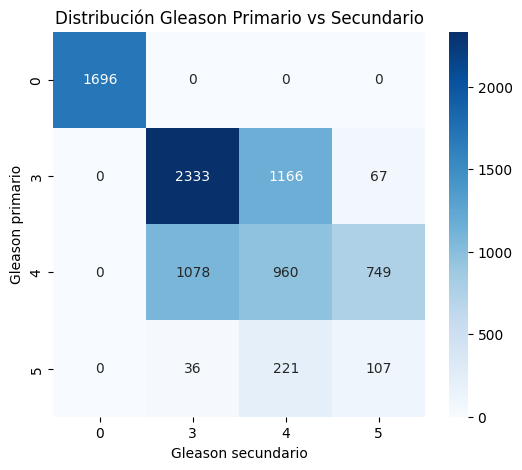

In [5]:
data_path_panda = '/workspace/data/datos_PANDAS.xlsx'
embedding_path_panda = '/workspace/data/pandas/patches'
df_pandas = count_df (data_path_panda, embedding_path_panda, 'PANDA',slide_col='image_id', printing=True)

Procesando embeddings: 100%|██████████| 230/230 [00:00<00:00, 915.46it/s]


228
Nº imagenes en Base de datos SICAP : 228
Nº de pacientes en SICAP: 228


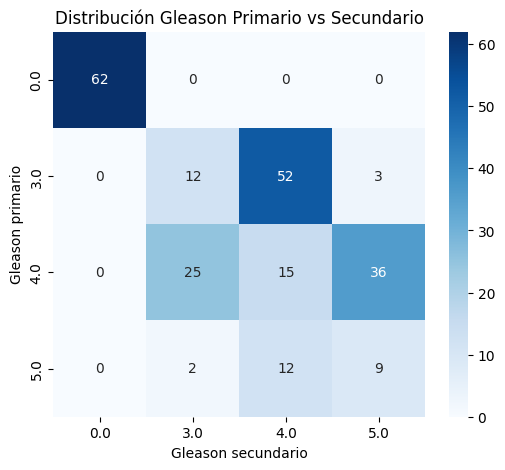

In [6]:
data_path = '/workspace/data/wsi_labels_changed_SICAP.xlsx'
embedding_path = '/workspace/data/features_SICAP/patches'
df_sicap = count_df (data_path, embedding_path, 'SICAP',slide_col='image_id', printing=True)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from sklearn.model_selection import train_test_split
import pandas as pd

def generar_tabla_resumen(df_pandas):
    # --- 1️⃣ Dividir en train, val y test ---
    train_val_idx, test_idx = train_test_split(
        df_pandas.index, test_size=0.1, stratify=df_pandas["gleason_score"]
    )

    train_idx, val_idx = train_test_split(
        train_val_idx, test_size=0.20, stratify=df_pandas.loc[train_val_idx]["gleason_score"]
    )

    # Crear subconjuntos
    df_train = df_pandas.loc[train_idx]
    df_val = df_pandas.loc[val_idx]
    df_test = df_pandas.loc[test_idx]

    # --- 2️⃣ Función auxiliar para contar clases ---
    def contar_por_columna(df, columna):
        return df[columna].value_counts().sort_index()

    # --- 3️⃣ Construir tablas ---
    tipos = ['gleason_primary', 'gleason_secondary', 'gleason_score']
    tablas = {}

    for tipo in tipos:
        # Combinar en un solo DataFrame
        tabla = pd.concat([
            contar_por_columna(df_train, tipo).rename('Train'),
            contar_por_columna(df_val, tipo).rename('Validation'),
            contar_por_columna(df_test, tipo).rename('Test')
        ], axis=1).fillna(0).astype(int)

        tablas[tipo] = tabla

    # --- 4️⃣ Mostrar resultados ---
    for nombre, tabla in tablas.items():
        print(f"\n📊 Tabla resumen por {nombre.replace('_', ' ').title()}")
        print(tabla)
    
    return tablas  # Devuelve un diccionario con las 3 tablas


In [6]:
tabla = generar_tabla_resumen(df_pandas)


📊 Tabla resumen por Gleason Primary
   Train  Validation  Test
0   1221         305   170
3   2582         639   345
4   1985         503   299
5    268          68    28

📊 Tabla resumen por Gleason Secondary
   Train  Validation  Test
0   1221         305   170
3   2465         630   352
4   1714         410   223
5    656         170    97

📊 Tabla resumen por Gleason Score
    Train  Validation  Test
0    1221         305   170
6    1680         420   233
7    1615         404   225
8     765         192   106
9     698         175    97
10     77          19    11


In [1]:
import os
import pandas as pd

# -------- CONFIGURACIÓN --------
carpeta = "/workspace/data/features_SICAP/patches_png"
excel_path = "/workspace/data/patch_coord_2.xlsx"

col_slide = "Slide_ID"
col_x = "X"
col_y = "Y"
# --------------------------------


# --- 1. Cargar Excel ---
df_excel = pd.read_excel(excel_path)

# Validación
for col in [col_slide, col_x, col_y]:
    if col not in df_excel.columns:
        raise ValueError(f"❌ La columna '{col}' no existe en el Excel.")


# --- 2. Extraer información de archivos ---
patchid_list = []
coord_x_list = []
coord_y_list = []
file_list = []

for archivo in os.listdir(carpeta):
    if not archivo.lower().endswith((".png", ".jpg", ".jpeg", ".h5")):
        continue  # ignora otros tipos de archivo

    nombre = os.path.splitext(archivo)[0]  # quitar extensión
    
    # Ejemplo:   19B008091A_4x3200_y4560
    try:
        patch_id = nombre.split("x")[0][:-1]      # "19B008091A_4"
        coords = nombre.split("x")[1]             # "3200_y4560"

        coord_x = coords.split("_")[0]            # "3200"
        coord_y = coords.split("y")[1]            # "4560"
    except Exception as e:
        print(f"⚠️ No se pudo parsear el nombre: {archivo}")
        continue

    patchid_list.append(patch_id)
    coord_x_list.append(int(coord_x))
    coord_y_list.append(int(coord_y))
    file_list.append(archivo)


# --- 3. Crear dataframe nuevo con los datos extraídos ---
df_files = pd.DataFrame({
    "archivo": file_list,
    "Slide_ID": patchid_list,
    "X": coord_x_list,
    "Y": coord_y_list
})

print("\n📘 DataFrame generado desde los archivos:")
print(df_files.head())


# --- 4. Comparación con el Excel ---
df_merged = df_files.merge(
    df_excel[[col_slide, col_x, col_y]],
    on=["Slide_ID", "X", "Y"],
    how="left",
    indicator=True
)

# Archivos encontrados en Excel
df_existen = df_merged[df_merged["_merge"] == "both"]

# Archivos NO encontrados en Excel
df_no_existen = df_merged[df_merged["_merge"] == "left_only"]


print("\n✅ Coincidencias encontradas:", len(df_existen))
print("❌ No encontradas:", len(df_no_existen))



📘 DataFrame generado desde los archivos:
                         archivo       Slide_ID     X     Y
0  16B0003388_13_x1105_y3113.png  16B0003388_13  1105  3113
1  16B0003388_13_x1105_y3625.png  16B0003388_13  1105  3625
2  16B0003388_13_x1105_y4137.png  16B0003388_13  1105  4137
3  16B0003388_13_x1617_y3625.png  16B0003388_13  1617  3625
4  16B0003388_13_x1617_y4137.png  16B0003388_13  1617  4137

✅ Coincidencias encontradas: 2847
❌ No encontradas: 4859


In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch import Tensor

from torch_geometric.nn import GATv2Conv
from torch_geometric.data import Data
from torch_geometric.data import Batch
from torch_geometric.utils import softmax

import timm
import numpy

import os
#from conch.open_clip_custom import create_model_from_pretrained


from transformers import BitsAndBytesConfig, PretrainedConfig, PreTrainedModel, BertModel, AutoConfig, AutoModel, BertConfig

from peft import get_peft_model,IA3Config #, LoraConfig

model_name = 'keep'
pretrain = True
class KEEPConfig(PretrainedConfig):
    model_type = "keep"  # 

    def __init__(
        self,
        vision_config=None,  # Vision Encoder
        text_config=None,    # Text Encoder
        projection_dim=768,  
        **kwargs,
    ):
        super().__init__(**kwargs)
        self.vision_config = vision_config
        self.text_config = text_config
        self.projection_dim = projection_dim
        

class KEEPModel(PreTrainedModel):
    config_class = KEEPConfig  # 

    def __init__(self, config):
        super().__init__(config)

        # Vision Encoder 
        self.visual = timm.create_model("vit_large_patch16_224",
                                        pretrained=False,
                                        img_size=224,
                                        patch_size=16,
                                        init_values=1e-5,
                                        num_classes=0,
                                        dynamic_img_size=True,
        )

        self.visual_head = nn.Sequential(
                    nn.Linear(self.visual.num_features, config.projection_dim),
                    nn.GELU(),
                    nn.Linear(config.projection_dim, config.projection_dim)
                )

        # Text Encoder
        text_config =  BertConfig(**config.text_config)
        self.text = BertModel(text_config)
        
        self.logit_scale = nn.Parameter(torch.ones([]) * numpy.log(1 / 0.04))

    def encode_image(self, image_inputs):
        vision_features = self.visual(image_inputs)  # [batch_size, vision_dim]
        vision_features =  torch.nn.functional.normalize(self.visual_head(vision_features), dim=-1)  # [batch_size, projection_dim]
        
        return vision_features
    
    def encode_text(self, text_inputs):
        text_features = torch.nn.functional.normalize(self.text(**text_inputs).pooler_output, dim=-1)  # [batch_size, text_dim]
        return text_features
    
    
    def forward(self, image_inputs, text_inputs):
        vision_features = self.encode_image(image_inputs)
        
        text_features = self.encode_text(text_inputs)

        return {
            "vision_features": vision_features,  
            "text_features": text_features}
         
AutoConfig.register(model_name, KEEPConfig)
AutoModel.register(KEEPConfig, KEEPModel)
    
bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,                      # Modelo cuantificado en 4 bits 
        bnb_4bit_compute_dtype=torch.float16,   # Float16 para maentener la velocidad y precision 
        bnb_4bit_use_double_quant=True,         # Usa doble cuanticicacion
        bnb_4bit_quant_type="nf4",              # Variante de tipo de cuqntificacion de 4 bits 
    )
    
model_path = '/workspace/data/MODELS/model_keep/'
checkpoint_path= '/workspace/data/MODELS/model_keep/pytorch_model.bin'
config = AutoConfig.from_pretrained(model_path + 'config.json',
                                trust_remote_code=True,             # Ejecuta el codio en remoto
                                quantization_config=bnb_config,     # Introduce la configuracion de carga del modelo
                                #force_download=True,                # Descarga del modelo 
                                low_cpu_mem_usage = True            # Reduce memoria en la carga
)
model = AutoModel.from_config(config)
state_dict = torch.load(checkpoint_path, map_location='cpu')
model.load_state_dict(state_dict, strict=True)
    
# Activar gradient checkpointing para reducir VRAM
if hasattr(model, "gradient_checkpointing"):
    model.gradient_checkpointing = True

model.config.use_cache = False  # Reducir uso de memoria durante forward

# Identificar módulos lineales donde aplicar IA3
target_modules = []
for name, module in model.named_modules():
    if isinstance(module, nn.Linear) and any(
        key in name for key in ["attn.qkv", "attn.proj"]#, "mlp.fc1", "mlp.fc2"]
    ):
        target_modules.append(name)

ia3_config = IA3Config(
    target_modules=target_modules,
    feedforward_modules=target_modules,
    task_type="FEATURE_EXTRACTION" # SEQ_CLS
)

ia3_model = get_peft_model(model, ia3_config)

parameters = 0
train_parameters = 0

model = torch.compile(model) # Activar torch.compile si usas PyTorch 2.0+
# Congelar TODO menos IA
for name, param in ia3_model.named_parameters():
    parameters += param.numel()
    if pretrain == True:
        if "visual.blocks.23.attn.proj.ia3_l" or "visual.blocks.22.attn.proj.ia3_l" or "visual.blocks.21.attn.proj.ia3_l" or "visual.blocks.20.attn.proj.ia3_l" or "visual.blocks.19.attn.proj.ia3_l" in name:
            train_parameters += param.numel()
            param.requires_grad = True
        else:
            param.requires_grad = False
    else:
        param.requires_grad = False
ia3_model.print_trainable_parameters()
print(f"Total parameters: {parameters} | Trainable parameters: {train_parameters} ")


trainable params: 414,259,969 || all params: 414,259,969 || trainable%: 100.0
Total parameters: 414259969 | Trainable parameters: 414259969 
